In [13]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from double_stopping_env import HouseSellingEnv
from tabulate import tabulate

In [14]:
class QLearningUCB:
    def __init__(self, env, epsilon=1, gamma=1, episodes=100000, alpha=0.01, c=1.0):
        self.env = env
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.episodes = episodes
        self.actions = [0, 1]
        self.c = c

        self.Q = np.zeros((self.env.horizon + 1, len(self.env.states), 2, 2))
        self.N = np.ones_like(self.Q)  # visit counts
        self.ep_rewards = []
        self.start_states = []

        for t in range(self.env.horizon + 1):
            for s in range(len(self.env.states)):
                for z in [1, 2]:
                    self.Q[t, s, z - 1, 1] = s - (z - 1) * self.env.cost

    def select_action(self, t, s, z):
        q_vals = self.Q[t, s, z - 1]
        bonus = self.c * np.sqrt(np.log(np.sum(self.N[t, s, z - 1]) + 1) / self.N[t, s, z - 1])
        return np.argmax(q_vals + bonus)

    def reward(self, s, action, z):
        if action == 0:
            return -self.env.cost
        else:
            if z == 2:
                return s - self.env.cost
            elif z == 1:
                return s
        return 0

    def greedy(self, t, s, z):
        return np.argmax(self.Q[t, s, z - 1])

    def simulate_episode(self):
        sequence = self.env.generate_sequence()
        self.start_states.append(sequence[0])
        z = 2
        ep_reward = 0
        for t in range(self.env.horizon):
            s = sequence[t]
            a = self.select_action(t, s, z)
            r = self.reward(s, a, z)
            ep_reward += r
            self.N[t, s, z - 1, a] += 1

            if t < self.env.horizon - 1:
                next_s = sequence[t + 1]
                next_z = z if a == 0 else z - 1
                if next_z > 0:
                    next_max_q = np.max(self.Q[t + 1, next_s, next_z - 1])
                else:
                    next_max_q = 0

                self.Q[t, s, z - 1, a] += self.alpha * (r + self.gamma * next_max_q - self.Q[t, s, z - 1, a])

                if a == 1 and next_z == 0:
                    break
                z = next_z
            else:
                self.Q[t, s, z - 1, a] += self.alpha * (r - self.Q[t, s, z - 1, a])
                break
        self.ep_rewards.append(ep_reward)

    def get_values(self):
        V_1 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        V_2 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        for t in range(self.env.horizon + 1):
            for s in range(len(self.env.states)):
                V_1[t, s] = max(self.Q[t, s, 0, a] for a in self.actions)
                V_2[t, s] = max(self.Q[t, s, 1, a] for a in self.actions)
        return V_1, V_2

    def get_regret(self, V_2):
        self.training_regret = np.zeros(self.episodes)
        self.testing_regret = np.zeros(self.episodes)
        for episode in tqdm(range(self.episodes), desc="Regret Calculation (UCB)"):
            self.training_regret[episode] = (
                V_2[0][self.start_states[episode]] - self.ep_rewards[episode]
            )
            sequence = self.env.generate_sequence()
            start_state = sequence[0]
            z = 2
            ep_reward = 0
            for t in range(self.env.horizon):
                s = sequence[t]
                a = self.greedy(t, s, z)
                r = self.reward(s, a, z)
                ep_reward += r
                if t < self.env.horizon - 1:
                    next_z = z if a == 0 else z - 1
                    if a == 1 and next_z == 0:
                        break
                    z = next_z
                else:
                    break
            self.testing_regret[episode] = V_2[0][start_state] - ep_reward
        return self.training_regret, self.testing_regret

    def get_average_rewards(self):
        self.average_rewards = np.zeros(self.episodes)
        average_reward = 0
        for episode in tqdm(range(self.episodes), desc="Average Reward (UCB)"):
            average_reward += (1 / (episode + 1)) * (
                self.ep_rewards[episode] - average_reward
            )
            self.average_rewards[episode] = average_reward
        return self.average_rewards

In [15]:
class QLearningGap:
    def __init__(self, env, epsilon=1, gamma=1, episodes=100000, alpha=0.01, gap_threshold=1e-2):
        self.env = env
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.episodes = episodes
        self.actions = [0, 1]
        self.gap_threshold = gap_threshold
        self.Q = np.zeros((self.env.horizon + 1, len(self.env.states), 2, 2))
        self.ep_rewards = []
        self.start_states = []

        for t in range(self.env.horizon + 1):
            for s in range(len(self.env.states)):
                for z in [1, 2]:
                    self.Q[t, s, z - 1, 1] = s - (z - 1) * self.env.cost

    def select_action(self, t, s, z):
        q_vals = self.Q[t, s, z - 1]
        gap = np.abs(q_vals[0] - q_vals[1])
        if gap < self.gap_threshold:
            return np.random.choice(self.actions)
        return np.argmax(q_vals)

    def reward(self, s, action, z):
        if action == 0:
            return -self.env.cost
        else:
            if z == 2:
                return s - self.env.cost
            elif z == 1:
                return s
        return 0

    def greedy(self, t, s, z):
        return np.argmax(self.Q[t, s, z - 1])

    def simulate_episode(self):
        sequence = self.env.generate_sequence()
        self.start_states.append(sequence[0])
        z = 2
        ep_reward = 0
        for t in range(self.env.horizon):
            s = sequence[t]
            a = self.select_action(t, s, z)
            r = self.reward(s, a, z)
            ep_reward += r

            if t < self.env.horizon - 1:
                next_s = sequence[t + 1]
                next_z = z if a == 0 else z - 1
                if next_z > 0:
                    next_max_q = np.max(self.Q[t + 1, next_s, next_z - 1])
                else:
                    next_max_q = 0

                self.Q[t, s, z - 1, a] += self.alpha * (r + self.gamma * next_max_q - self.Q[t, s, z - 1, a])

                if a == 1 and next_z == 0:
                    break
                z = next_z
            else:
                self.Q[t, s, z - 1, a] += self.alpha * (r - self.Q[t, s, z - 1, a])
                break
        self.ep_rewards.append(ep_reward)

    def get_values(self):
        V_1 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        V_2 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        for t in range(self.env.horizon + 1):
            for s in range(len(self.env.states)):
                V_1[t, s] = max(self.Q[t, s, 0, a] for a in self.actions)
                V_2[t, s] = max(self.Q[t, s, 1, a] for a in self.actions)
        return V_1, V_2

    def get_regret(self, V_2):
        self.training_regret = np.zeros(self.episodes)
        self.testing_regret = np.zeros(self.episodes)
        for episode in tqdm(range(self.episodes), desc="Regret Calculation (Gap)"):
            self.training_regret[episode] = (
                V_2[0][self.start_states[episode]] - self.ep_rewards[episode]
            )
            sequence = self.env.generate_sequence()
            start_state = sequence[0]
            z = 2
            ep_reward = 0
            for t in range(self.env.horizon):
                s = sequence[t]
                a = self.greedy(t, s, z)
                r = self.reward(s, a, z)
                ep_reward += r
                if t < self.env.horizon - 1:
                    next_z = z if a == 0 else z - 1
                    if a == 1 and next_z == 0:
                        break
                    z = next_z
                else:
                    break
            self.testing_regret[episode] = V_2[0][start_state] - ep_reward
        return self.training_regret, self.testing_regret

    def get_average_rewards(self):
        self.average_rewards = np.zeros(self.episodes)
        average_reward = 0
        for episode in tqdm(range(self.episodes), desc="Average Reward (Gap)"):
            average_reward += (1 / (episode + 1)) * (
                self.ep_rewards[episode] - average_reward
            )
            self.average_rewards[episode] = average_reward
        return self.average_rewards

In [16]:
class QLearningRegret:
    def __init__(self, env, epsilon=1, gamma=1, episodes=100000, alpha=0.01):
        self.env = env
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.episodes = episodes
        self.actions = [0, 1]
        self.Q = np.zeros((self.env.horizon + 1, len(self.env.states), 2, 2))
        self.ep_rewards = []
        self.start_states = []

        for t in range(self.env.horizon + 1):
            for s in range(len(self.env.states)):
                for z in [1, 2]:
                    self.Q[t, s, z - 1, 1] = s - (z - 1) * self.env.cost

    def greedy(self, t, s, z):
        return np.argmax(self.Q[t, s, z - 1])

    def reward(self, s, action, z):
        if action == 0:
            return -self.env.cost
        else:
            if z == 2:
                return s - self.env.cost
            elif z == 1:
                return s
        return 0

    def simulate_episode(self):
        sequence = self.env.generate_sequence()
        self.start_states.append(sequence[0])
        z = 2
        ep_reward = 0
        for t in range(self.env.horizon):
            s = sequence[t]
            a = self.greedy(t, s, z)
            r = self.reward(s, a, z)
            ep_reward += r

            if t < self.env.horizon - 1:
                next_s = sequence[t + 1]
                next_z = z if a == 0 else z - 1

                if next_z > 0:
                    next_max_q = np.max(self.Q[t + 1, next_s, next_z - 1])
                else:
                    next_max_q = 0

                self.Q[t, s, z - 1, a] += self.alpha * (r + self.gamma * next_max_q - self.Q[t, s, z - 1, a])

                if a == 1 and next_z == 0:
                    break
                z = next_z
            else:
                self.Q[t, s, z - 1, a] += self.alpha * (r - self.Q[t, s, z - 1, a])
                break
        self.ep_rewards.append(ep_reward)

    def get_values(self):
        V_1 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        V_2 = np.zeros((self.env.horizon + 1, len(self.env.states)))
        for t in range(self.env.horizon + 1):
            for s in range(len(self.env.states)):
                V_1[t, s] = max(self.Q[t, s, 0, a] for a in self.actions)
                V_2[t, s] = max(self.Q[t, s, 1, a] for a in self.actions)
        return V_1, V_2

    def get_regret(self, V_2):
        self.training_regret = np.zeros(self.episodes)
        self.testing_regret = np.zeros(self.episodes)
        for episode in tqdm(range(self.episodes), desc="Regret Calculation (Q-Learning)"):
            self.training_regret[episode] = (
                V_2[0][self.start_states[episode]] - self.ep_rewards[episode]
            )
            sequence = self.env.generate_sequence()
            start_state = sequence[0]
            z = 2
            ep_reward = 0
            for t in range(self.env.horizon):
                s = sequence[t]
                a = self.greedy(t, s, z)
                r = self.reward(s, a, z)
                ep_reward += r
                if t < self.env.horizon - 1:
                    next_z = z if a == 0 else z - 1
                    if a == 1 and next_z == 0:
                        break
                    z = next_z
                else:
                    break
            self.testing_regret[episode] = V_2[0][start_state] - ep_reward
        return self.training_regret, self.testing_regret

    def get_average_rewards(self):
        self.average_rewards = np.zeros(self.episodes)
        average_reward = 0
        for episode in tqdm(range(self.episodes), desc="Average Reward (Q-Learning)"):
            average_reward += (1 / (episode + 1)) * (
                self.ep_rewards[episode] - average_reward
            )
            self.average_rewards[episode] = average_reward
        return self.average_rewards

In [ ]:
env = HouseSellingEnv(horizon=5, cost=1, max_offer=10)

In [18]:
ucb_agent = QLearningUCB(env)
for _ in tqdm(range(ucb_agent.episodes), desc="UCB Episodes"):
    ucb_agent.simulate_episode()
V_1_ucb, V_2_ucb = ucb_agent.get_values()
training_regret_ucb, testing_regret_ucb = ucb_agent.get_regret(V_2_ucb)
average_rewards_ucb = ucb_agent.get_average_rewards()

Average Reward (UCB): 100%|██████████| 100000/100000 [00:00<00:00, 1857489.43it/s]


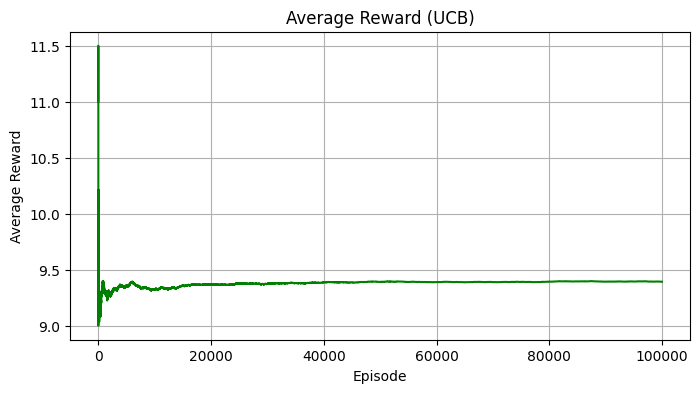

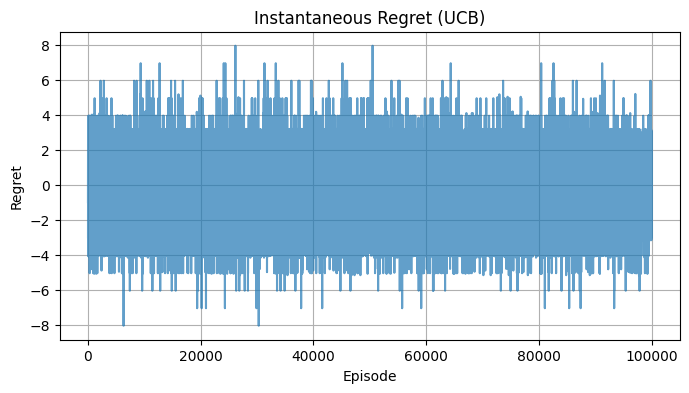

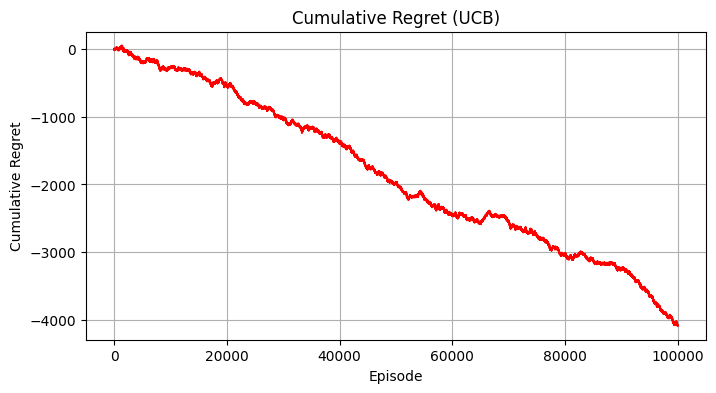

In [19]:
plt.figure(figsize=(8, 4))
plt.plot(average_rewards_ucb, color="green")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.title("Average Reward (UCB)")
plt.grid(True)
plt.show()

# Plot instantaneous regret for regret_agent
plt.figure(figsize=(8, 4))
plt.plot(testing_regret_ucb, alpha=0.7)
plt.xlabel("Episode")
plt.ylabel("Regret")
plt.title("Instantaneous Regret (UCB)")
plt.grid(True)
plt.show()

# Plot cumulative regret for regret_agent
cum_regret = np.cumsum(testing_regret_ucb)
plt.figure(figsize=(8, 4))
plt.plot(cum_regret, color="red")
plt.xlabel("Episode")
plt.ylabel("Cumulative Regret")
plt.title("Cumulative Regret (UCB)")
plt.grid(True)
plt.show()

In [20]:
gap_agent = QLearningGap(env)
for _ in tqdm(range(gap_agent.episodes), desc="Gap Episodes"):
    gap_agent.simulate_episode()
V_1_gap, V_2_gap = gap_agent.get_values()
training_regret_gap, testing_regret_gap = gap_agent.get_regret(V_2_gap)
average_rewards_gap = gap_agent.get_average_rewards()


Average Reward (Gap): 100%|██████████| 100000/100000 [00:00<00:00, 1887285.82it/s]


In [21]:
regret_agent = QLearningRegret(env)
for _ in tqdm(range(regret_agent.episodes), desc="Regret Episodes"):
    regret_agent.simulate_episode()
V_1_regret, V_2_regret = regret_agent.get_values()
training_regret_regret, testing_regret_regret = regret_agent.get_regret(V_2_regret)
average_rewards_regret = regret_agent.get_average_rewards()

Average Reward (Q-Learning): 100%|██████████| 100000/100000 [00:00<00:00, 1886691.56it/s]


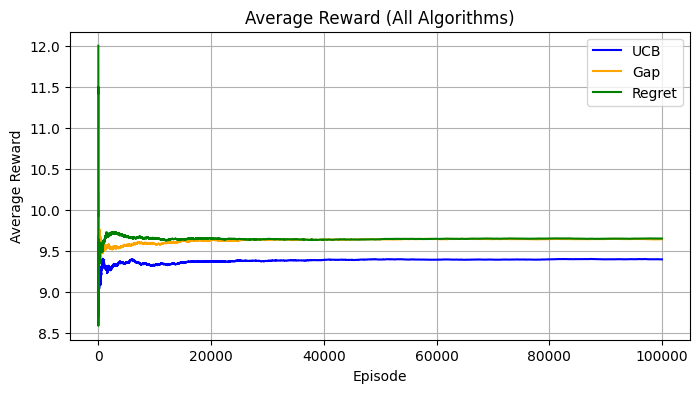

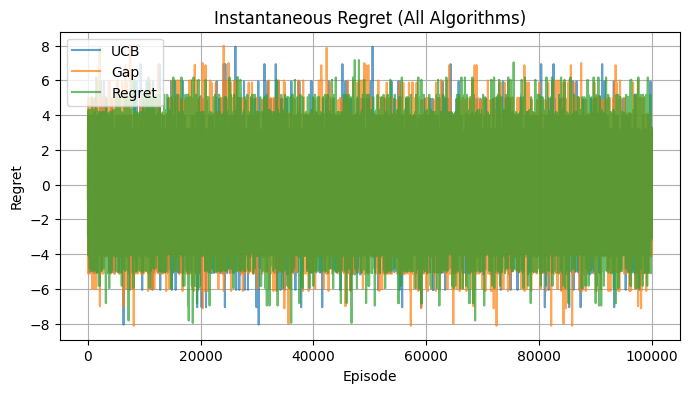

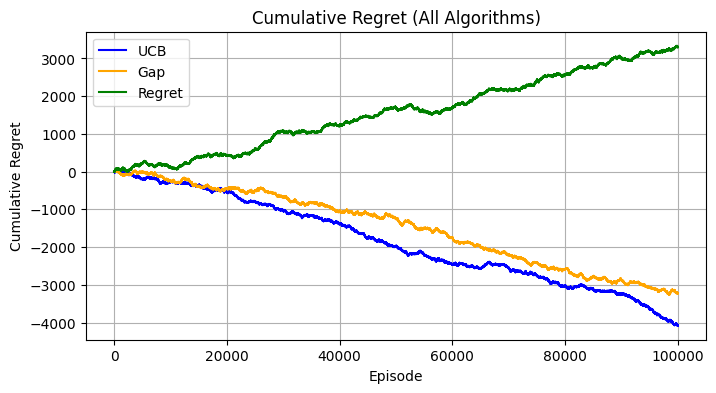

In [22]:
# Plot average reward for all agents
plt.figure(figsize=(8, 4))
plt.plot(average_rewards_ucb, color="blue", label="UCB")
plt.plot(average_rewards_gap, color="orange", label="Gap")
plt.plot(average_rewards_regret, color="green", label="Regret")
plt.xlabel("Episode")
plt.ylabel("Average Reward")
plt.title("Average Reward (All Algorithms)")
plt.legend()
plt.grid(True)
plt.show()

# Plot instantaneous regret for all agents
plt.figure(figsize=(8, 4))
plt.plot(testing_regret_ucb, alpha=0.7, label="UCB")
plt.plot(testing_regret_gap, alpha=0.7, label="Gap")
plt.plot(testing_regret_regret, alpha=0.7, label="Regret")
plt.xlabel("Episode")
plt.ylabel("Regret")
plt.title("Instantaneous Regret (All Algorithms)")
plt.legend()
plt.grid(True)
plt.show()

# Plot cumulative regret for all agents
plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(testing_regret_ucb), color="blue", label="UCB")
plt.plot(np.cumsum(testing_regret_gap), color="orange", label="Gap")
plt.plot(np.cumsum(testing_regret_regret), color="green", label="Regret")
plt.xlabel("Episode")
plt.ylabel("Cumulative Regret")
plt.title("Cumulative Regret (All Algorithms)")
plt.legend()
plt.grid(True)
plt.show()